# Part B2 - See the results (BiLSTM vs BERT)
**Ali | 6:07 PM**

> **How to use this notebook:** Runtime > **Run all**. No GPU needed. It loads our finished results from GitHub, so everyone sees the same numbers.

---

## Step 1 - Load the saved predictions

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "sagarh12/forge-workshop/main/"
)

bilstm = pd.read_csv(
    BASE_URL + "outputs/predictions/bilstm_predictions.csv"
)

bert = pd.read_csv(
    BASE_URL + "outputs/predictions/bert_finetuned_predictions.csv"
)

assert len(bilstm) == len(bert) == 2610

assert bilstm["utterance"].equals(bert["utterance"])
assert bilstm["true_label"].equals(bert["true_label"])

comparison = pd.DataFrame({
    "utterance": bert["utterance"],
    "actual": bert["true_label"],
    "BiLSTM": bilstm["predicted_label"],
    "BERT": bert["predicted_label"]
})

def show_results(data):
    display(
        data.style
        .set_properties(
            subset=["utterance"],
            **{
                "text-align": "left",
                "white-space": "normal",
                "min-width": "250px",
                "max-width": "450px"
            }
        )
        .set_properties(
            subset=["actual", "BiLSTM", "BERT"],
            **{
                "text-align": "center",
                "min-width": "75px"
            }
        )
        .hide(axis="index")
    )

print("Both models loaded successfully!")
print("Test samples:", len(comparison))

display(comparison.head(5))

Both models loaded successfully!
Test samples: 2610


,utterance,actual,BiLSTM,BERT
0,Why do all you're coffee mugs have numbers on the bottom?,surprise,neutral,surprise
1,"Oh. That's so Monica can keep track. That way if one on them is missing, she can be like, Where's number 27?!'",anger,neutral,neutral
2,Y'know what?,neutral,neutral,neutral
3,"Come on, Lydia, you can do it.",neutral,neutral,neutral
4,Push!,joy,joy,anger


## Step 2 - Look at 10 random lines

In [ ]:
comparison.sample(10, random_state=42)

,utterance,actual,BiLSTM,BERT
1475,"Okay, okay. Umm, well ah, maybe he, maybe he feels awkward because you are my boss.",neutral,neutral,neutral
1835,"It's okay. Chandler, are you afraid of me or something?",neutral,neutral,sadness
210,If you give up every time you'd have a fight with someone you'd never be with anyone longer thanOhhh!,anger,anger,anger
2434,Is not.,anger,neutral,neutral
2366,"Oh, wait a second! I didn't say I wasn't free!",surprise,surprise,anger
1557,"Well, honey that was pretty obvious.",sadness,neutral,neutral
1755,"Thanks for the coffee, or bedankt voor de koffie, Gunter.",neutral,neutral,neutral
211,"So, this isn't over?",neutral,neutral,neutral
1736,Okay?,neutral,neutral,neutral
175,Like me tiny doctor!',anger,anger,anger


## Step 3 - Scores: accuracy and macro F1

,Accuracy,Macro F1
Model,,
BiLSTM,0.6042,0.3368
BERT,0.6387,0.4350


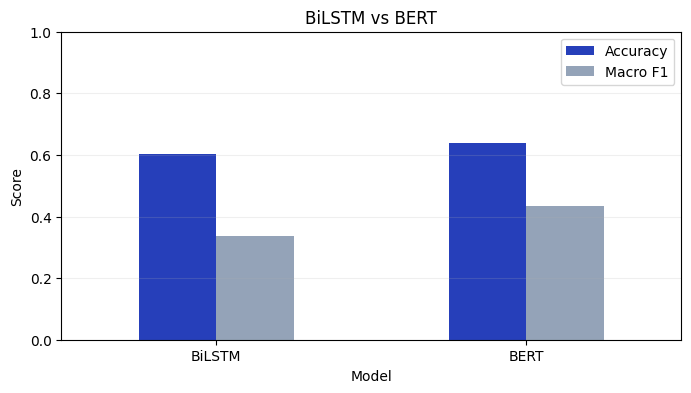

In [ ]:
labels = [
    "anger", "disgust", "fear", "joy",
    "neutral", "sadness", "surprise"
]

scores = []

for model_name in ["BiLSTM", "BERT"]:

    accuracy = accuracy_score(
        comparison["actual"],
        comparison[model_name]
    )

    macro_f1 = f1_score(
        comparison["actual"],
        comparison[model_name],
        labels=labels,
        average="macro",
        zero_division=0
    )

    scores.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

scores = pd.DataFrame(scores).set_index("Model")

display(scores.round(4))

scores.plot(
    kind="bar",
    figsize=(8, 4),
    rot=0,
    ylim=(0, 1),
    color=["#263fba", "#94a3b8"],
    title="BiLSTM vs BERT"
)

plt.ylabel("Score")
plt.grid(axis="y", alpha=0.2)
plt.show()

## Step 4 - Lines BERT got right but BiLSTM got wrong

In [ ]:
improved = comparison[
    (comparison["BiLSTM"] != comparison["actual"]) &
    (comparison["BERT"] == comparison["actual"])
]

print("Examples BERT got right but BiLSTM got wrong:")

display(improved.sample(5, random_state=42))

print("Total:", len(improved))

Examples BERT got right but BiLSTM got wrong:


,utterance,actual,BiLSTM,BERT
1856,Later is not good enough.,anger,neutral,anger
911,How could you not tell me that she has hair?,surprise,anger,surprise
1977,We said six!,anger,joy,anger
96,"I mean, enough of the silliness!",anger,joy,anger
739,"Ow, no woo-hooing,' no woo-hooing.'",anger,neutral,anger


Total: 327


## Step 5 - Lines both models got wrong

In [ ]:
both_wrong = comparison[
    (comparison["BiLSTM"] != comparison["actual"]) &
    (comparison["BERT"] != comparison["actual"])
]

print("Examples both models got wrong:")

display(both_wrong.sample(5, random_state=42))

print("Total:", len(both_wrong))

Examples both models got wrong:


,utterance,actual,BiLSTM,BERT
1723,Hey!!,anger,joy,joy
286,"Yes!! Yes! Yes! Yes!! That's my Dad, that's Frank! Yeah! I'm sorry I'm getting all flingy.",surprise,joy,joy
280,"Oh. God, crazy Chandler. He spun me...off...the...bed!",joy,neutral,anger
776,You're flingin'-flangin' right I am!,joy,anger,anger
1127,"Oh, my Bing-a-ling. I'll wait for you. Do you even know how long you're going to be gone?",sadness,neutral,anger


Total: 706


## Step 6 - Which emotions each model predicts

,Actual,BiLSTM,BERT
anger,345,251,330
disgust,68,0,11
fear,50,11,18
joy,402,376,441
neutral,1256,1702,1319
sadness,208,45,174
surprise,281,225,317


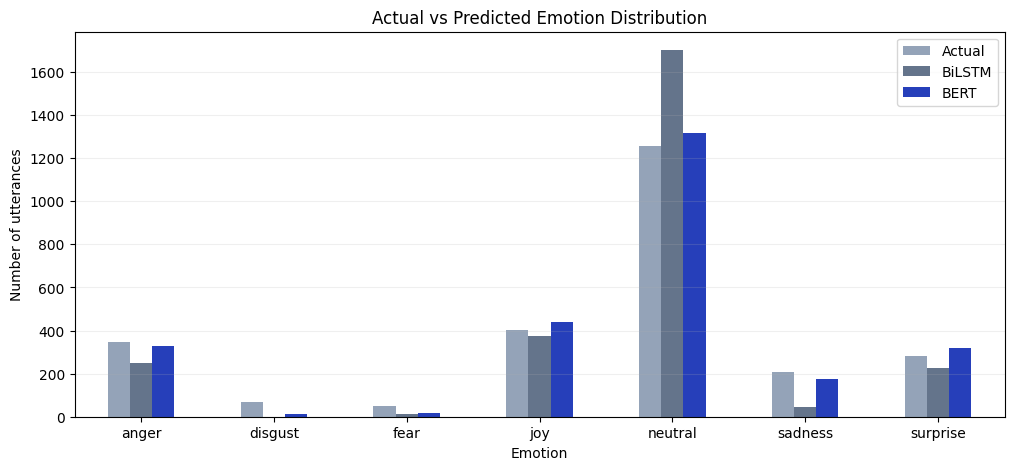

In [ ]:
distribution = pd.DataFrame({
    "Actual": comparison["actual"].value_counts(),
    "BiLSTM": comparison["BiLSTM"].value_counts(),
    "BERT": comparison["BERT"].value_counts()
})

distribution = distribution.reindex(labels).fillna(0).astype(int)

display(distribution)

distribution.plot(
    kind="bar",
    figsize=(12, 5),
    rot=0,
    color=["#94a3b8", "#64748b", "#263fba"]
)

plt.title("Actual vs Predicted Emotion Distribution")
plt.ylabel("Number of utterances")
plt.xlabel("Emotion")
plt.grid(axis="y", alpha=0.2)
plt.show()

## Step 7 - Your turn: guess the emotion

In [ ]:
import ipywidgets as widgets
from IPython.display import display

sentence = comparison.sample(1).iloc[0]

print("Sentence:")
print(sentence["utterance"])

guess = widgets.Dropdown(
    options=labels,
    description="Emotion:"
)

button = widgets.Button(
    description="Reveal answers"
)

output = widgets.Output()

def reveal_answer(event):

    with output:
        output.clear_output()

        print("Your prediction:", guess.value)
        print("Actual label:", sentence["actual"])
        print("BiLSTM:", sentence["BiLSTM"])
        print("BERT:", sentence["BERT"])

button.on_click(reveal_answer)

display(guess, button, output)

Sentence:
No. No-no. No. What would


Dropdown(description='Emotion:', options=('anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise')…

Button(description='Reveal answers', style=ButtonStyle())

Output()